# 03 - Let's estimate the uplift with DML

**Business Loves Uplift: Causal Impact Evaluation With Python**<br>
ODSC AI West 2026 · Alex Molak · [CausalPython.io](https://causalpython.io)

<a href="https://colab.research.google.com/github/AlxndrMlk/talks-and-workshops/blob/main/2026-10--odsc-ai/03%20-%20Double%20machine%20learning.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

**The story.** A retailer's field sales reps each look after 120-200 stores. The data team built a recommender that tells a rep which products (SKUs) to act on in each store. How much does it lift store sales?

The data is synthetic, so we know the true answer. Weekly sales are in k$ per store.

**The rollout.** After the A/B test, management gave the recommender to the reps it judged strongest. Did it work, and how much?

We have one row per rep. The reps weren't randomized, so we need a causal graph, an adjustment set, and an estimator that doesn't overfit: double machine learning (DML).

In [35]:
# Colab only: install the packages and get the data generator (locally, use the workshop env)
import sys
if "google.colab" in sys.modules:
    !pip install -q dowhy==0.14 econml==0.17.0
    !wget -q -nc https://raw.githubusercontent.com/AlxndrMlk/talks-and-workshops/main/2026-10--odsc-ai/dml_data.py

In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from dowhy import CausalModel
from econml.dml import DML
from econml.sklearn_extensions.linear_model import StatsModelsLinearRegression
from sklearn.linear_model import LassoCV, LogisticRegressionCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import dml_data as dd

BLUE, GOLD, GREY, RED, DARK = "#0057d9", "#c8860d", "#bbbbbb", "#c0392b", "#222222"
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})

In [53]:
d = dd.make_datasets()     # seed 57: everyone gets the same data
truth = d["truth"]         # the answer key; we only peek at it at the end
print(dd.fingerprint(d))

5021.560


## The data

| column | meaning |
|---|---|
| `recommender` | 1 if the rep got the recommender (treatment) |
| `sales_post` | mean weekly sales per store after it went live (outcome) |
| `experience` | years in the job |
| `store_size`, `footfall` | the rep's average store |
| `rec_skus` | recommended products acted on, per store per month |
| `bonus` | 1 if the rep got the adoption bonus |

In [54]:
reps = d["reps_observed"]
reps.head()

,rep_id,recommender,sales_post,experience,store_size,footfall,rec_skus,bonus
0,0,0,20.405,7.3,396.1,1712.0,4,0
1,1,1,20.196,7.7,364.8,1171.0,14,0
2,2,1,28.384,10.4,472.5,1762.0,16,1
3,3,1,24.841,9.8,439.3,1469.0,14,1
4,4,1,25.939,6.9,369.7,1875.0,19,1


In [55]:
reps.groupby("recommender")[["experience", "store_size", "footfall", "sales_post"]].mean().round(2)

,experience,store_size,footfall,sales_post
recommender,,,,
0,6.0,402.07,1530.34,19.84
1,7.2,408.33,1515.28,22.97


Reps with the recommender are more experienced, and experienced reps sell more anyway. A plain difference in sales mixes the effect with this difference.

In [56]:
naive = reps.groupby("recommender").sales_post.mean().diff().iloc[-1]
print(f"naive difference: {naive:.2f} k$ per store-week")

naive difference: 3.13 k$ per store-week


## The graph

- **Confounder:** management picked the reps it judged strongest, so `experience` drives both who got the recommender and sales.
- **Drive sales only:** `store_size` and `footfall`. Nobody got the recommender because of them.
- **Mediator:** the recommender works through the products reps act on. `rec_skus` sits on the causal path.
- **Collider:** reps with the recommender get an adoption bonus if their sales reach a target. `bonus` is caused by both the recommender and sales.
- **Hidden confounder:** what if something we didn't measure drives both who got the recommender and sales? We draw it as a dashed node. It's not in the data.

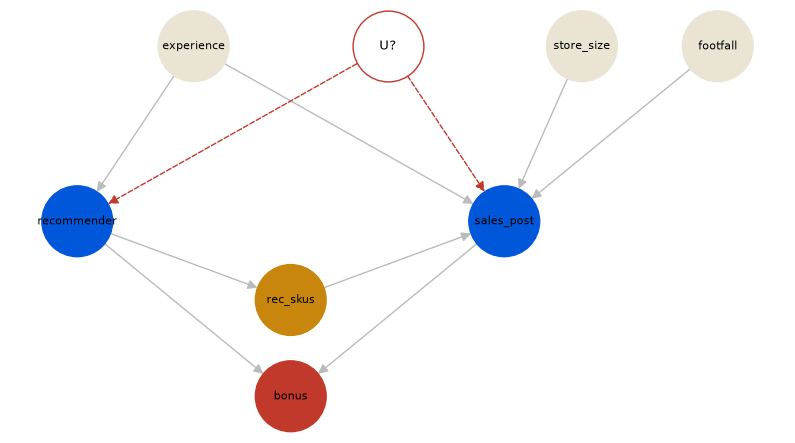

In [57]:
G = nx.DiGraph([
    ("experience", "recommender"), ("experience", "sales_post"),   # confounder
    ("store_size", "sales_post"), ("footfall", "sales_post"),      # drive sales only
    ("recommender", "rec_skus"), ("rec_skus", "sales_post"),       # mediator
    ("recommender", "bonus"), ("sales_post", "bonus"),             # collider
])

# draw it, with the hidden confounder U added for the picture only
pos = {"experience": (-1.0, 2.0), "U?": (1.0, 2.0), "store_size": (3.0, 2.0), "footfall": (4.4, 2.0),
       "recommender": (-2.2, 0), "sales_post": (2.2, 0), "rec_skus": (0, -0.9), "bonus": (0, -2.0)}
colors = {"recommender": BLUE, "sales_post": BLUE, "rec_skus": GOLD, "bonus": RED}

plt.figure(figsize=(10, 5.5))
nx.draw_networkx_edges(G, pos, edge_color=GREY, arrowsize=14, node_size=2600)
nx.draw_networkx_edges(nx.DiGraph([("U?", "recommender"), ("U?", "sales_post")]), pos, style="dashed",
                       edge_color=RED, arrowsize=14, node_size=2600)
nx.draw_networkx_nodes(G, pos, node_size=2600, node_color=[colors.get(n, "#e9e4d4") for n in G.nodes])
nx.draw_networkx_nodes(nx.DiGraph([("U?", "U?")]), pos, nodelist=["U?"], node_size=2600, node_color="white", edgecolors=RED)
nx.draw_networkx_labels(G, pos, font_size=8)
nx.draw_networkx_labels(G, pos, labels={"U?": "U?"}, font_size=9)
plt.axis("off")
plt.show()

## Identification with DoWhy

We give DoWhy the graph without `U`: our working assumption is that there's no hidden confounder. We'll stress test that assumption later.

DoWhy reads the adjustment set off the graph. Note that it leaves out the mediator and the collider.

In [58]:
model = CausalModel(data=reps.drop(columns="rep_id"), treatment="recommender", outcome="sales_post", graph=G)
estimand = model.identify_effect()
print("adjust for:", estimand.get_backdoor_variables())

adjust for: ['experience']


Only `experience` is needed to close the backdoor path. `store_size` and `footfall` aren't confounders, but they predict sales, so we also give them to the model: they make the estimate more precise.

## Estimation with DML

DML fits two ML models: one predicts sales from the covariates, the other predicts the treatment. It then regresses the sales residuals on the treatment residuals, with cross-fitting so no row is predicted by a model that saw it.

We use EconML's `DML` with a linear final model, through DoWhy. `experience` enters as `X`: the effect may change with it, which gives us the **CATE**. All covariates enter as `W`. Averaging the CATE over all reps gives the **ATE**.

In [59]:
def fit_dml(df, graph):
    """DML with X = experience; returns the causal model, the estimand and the estimate."""
    cm = CausalModel(data=df.drop(columns="rep_id"), treatment="recommender", outcome="sales_post", graph=graph)
    adjustment_set = cm.identify_effect(method_name="maximal-adjustment")
    estimate = cm.estimate_effect(
        adjustment_set, method_name="backdoor.econml.dml.DML", effect_modifiers=["experience"],
        method_params={"init_params": {"model_y": make_pipeline(StandardScaler(), LassoCV()),
                                       "model_t": make_pipeline(StandardScaler(), LogisticRegressionCV(max_iter=2000)),
                                       "model_final": StatsModelsLinearRegression(fit_intercept=False),
                                       "discrete_treatment": True, "cv": 5, "random_state": 0},
                       "fit_params": {}})
    return cm, adjustment_set, estimate


dml_model, full_set, dml_estimate = fit_dml(reps, G)
dml = dml_estimate._estimator_object
ate = float(dml.ate(X=reps[["experience"]]))
lo, hi = dml.ate_interval(X=reps[["experience"]])
print(f"adjust for: {full_set.get_backdoor_variables()}")
print(f"DML ATE: {ate:.2f} k$ [{lo:.2f}, {hi:.2f}]")

adjust for: ['footfall', 'experience', 'store_size']
DML ATE: 2.91 k$ [2.51, 3.32]


## The CATE: who benefits most?

The effect changes with experience. Juniors get more out of the recommender.

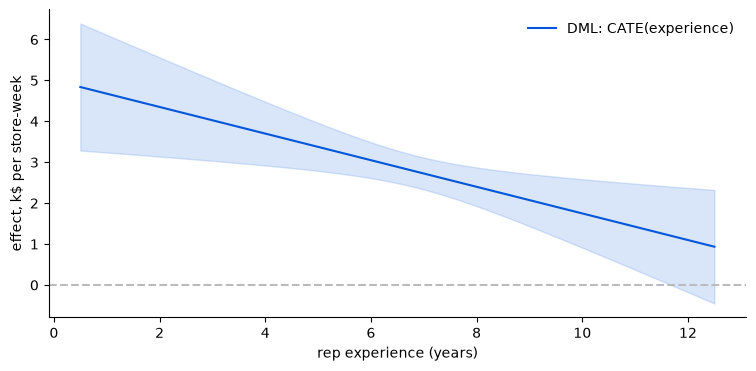

slope: -0.33 k$ per extra year of experience


In [60]:
grid = pd.DataFrame({"experience": np.linspace(reps.experience.min(), reps.experience.max(), 50)})
cate = np.ravel(dml.effect(grid))
cate_lo, cate_hi = map(np.ravel, dml.effect_interval(grid))

plt.fill_between(grid.experience, cate_lo, cate_hi, color=BLUE, alpha=0.15)
plt.plot(grid.experience, cate, color=BLUE, label="DML: CATE(experience)")
plt.axhline(0, color=GREY, ls="--")
plt.xlabel("rep experience (years)")
plt.ylabel("effect, k$ per store-week")
plt.legend(frameon=False)
plt.show()
print(f"slope: {dml.coef_.ravel()[0]:.2f} k$ per extra year of experience")

## Bad controls

More features isn't better identification. What if we "control for everything", including the mediator or the collider?

This is an identification problem, not an estimation one, so DML doesn't protect us. We refit the same DML model with each extra variable added to `W`.

In [61]:
covariates = ["experience", "store_size", "footfall"]
rows = []
for label, extra in [("experience, store_size, footfall", []),
                     ("+ rec_skus (mediator)", ["rec_skus"]),
                     ("+ bonus (collider)", ["bonus"])]:
    est = DML(model_y=make_pipeline(StandardScaler(), LassoCV()),
              model_t=make_pipeline(StandardScaler(), LogisticRegressionCV(max_iter=2000)),
              model_final=StatsModelsLinearRegression(fit_intercept=False),
              discrete_treatment=True, cv=5, random_state=0)
    est.fit(reps.sales_post, reps.recommender, X=reps[["experience"]], W=reps[covariates + extra])
    lo_, hi_ = est.ate_interval(X=reps[["experience"]])
    rows.append({"controls": label, "effect": float(est.ate(X=reps[["experience"]])), "lo": lo_, "hi": hi_})
bad = pd.DataFrame(rows)
bad.round(2)

,controls,effect,lo,hi
0,"experience, store_size, footfall",2.91,2.51,3.32
1,+ rec_skus (mediator),0.29,-0.61,1.18
2,+ bonus (collider),1.92,1.51,2.34


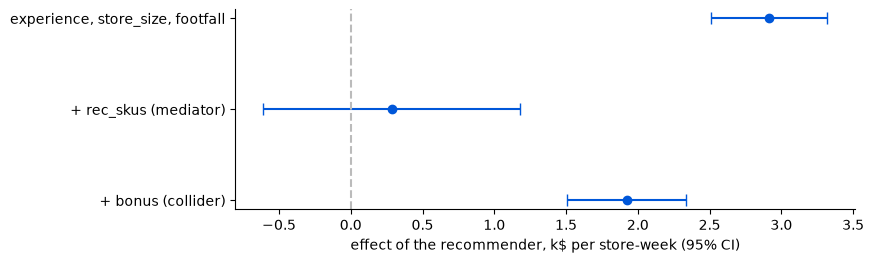

In [62]:
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.errorbar(bad.effect, bad.controls, xerr=[bad.effect - bad.lo, bad.hi - bad.effect], fmt="o", color=BLUE, capsize=4)
ax.axvline(0, color=GREY, ls="--")
ax.invert_yaxis()
ax.set_xlabel("effect of the recommender, k$ per store-week (95% CI)")
plt.show()

Controlling for the mediator blocks the path the effect travels on, so most of the effect disappears. The bonus depends on the outcome itself: once you control for it, you're comparing reps whose stores missed the target with the tool against everyone without it, so the tool looks worse than it is. DML can't fix a wrong adjustment set: identification comes from the graph.

## What if there's a confounder we didn't measure?

DoWhy's sensitivity analysis asks: how strong would a hidden confounder have to be to change our conclusion? Each point on the plot is a possible confounder, described by how much of the treatment (x) and of the outcome (y) it explains, as partial R². The contours show the estimate after removing its bias.

We can't measure the hidden confounder, but we can compare it to one we know: the triangles are confounders 1x, 2x and 3x as strong as rep experience.

We run it on the DML model we just fitted.

In [63]:
sensitivity = {k: dml_model.refute_estimate(full_set, dml_estimate,
                                            method_name="add_unobserved_common_cause",
                                            simulation_method="non-parametric-partial-R2",
                                            benchmark_common_causes=["experience"],
                                            effect_fraction_on_treatment=k,
                                            effect_fraction_on_outcome=k,
                                            plugin_reisz=True,
                                            plot_estimate=False)
               for k in [1, 2, 3]}
print(sensitivity[1])

Sensitivity Analysis to Unobserved Confounding using partial R^2 parameterization

Original Effect Estimate : 2.9148038692607696
Robustness Value : 0.61

Robustness Value (alpha=0.05) : 0.51

Interpretation of results :
Any confounder explaining less than 61.0% percent of the residual variance of both the treatment and the outcome would not be strong enough to explain away the observed effect i.e bring down the estimate to 0 

For a significance level of 5.0%, any confounder explaining more than 51.0% percent of the residual variance of both the treatment and the outcome would be strong enough to make the estimated effect not 'statistically significant'




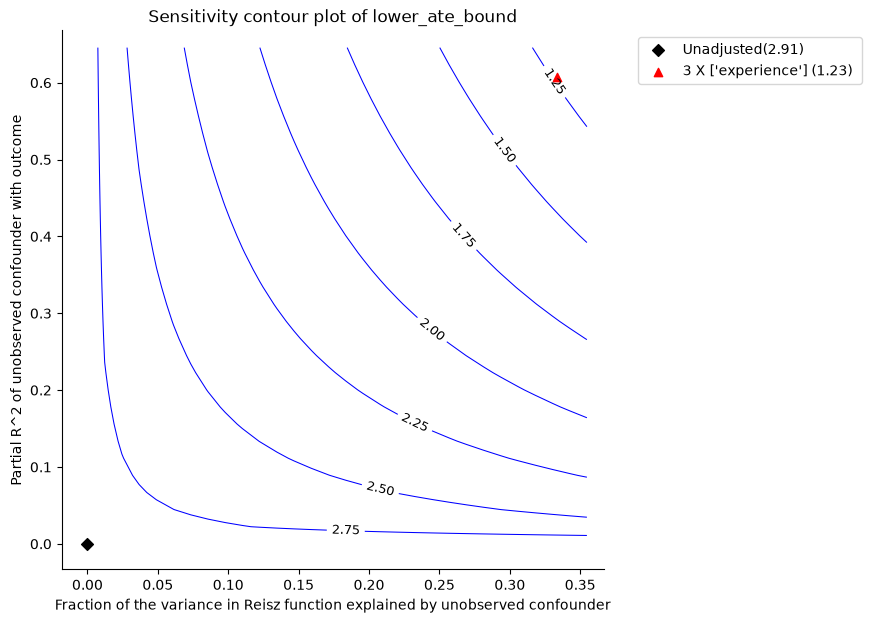

In [64]:
sensitivity[3].plot(plot_type="lower_ate_bound")

In [65]:
benchmarks = pd.concat([s.results for s in sensitivity.values()], ignore_index=True)
benchmarks.insert(0, "as strong as experience", ["1x", "2x", "3x"])
benchmarks.round(3)

,as strong as experience,r2tu_w,r2yu_tw,short estimate,bias,lower_ate_bound,upper_ate_bound,lower_confidence_bound,upper_confidence_bound
0,1x,0.111,0.202,2.915,0.485,2.430,3.400,1.998,3.811
1,2x,0.222,0.405,2.915,1.037,1.878,3.952,1.364,4.429
2,3x,0.334,0.607,2.915,1.680,1.234,4.595,0.588,5.193


A confounder up to 3x as strong as experience would shrink our estimate, but not to zero.

Even at 3x, the effect is still above 1 k$. In the real world, if we had strong reasons to belive that unobserved confounders are not 3x stronger than rep's experience, this analysis would provide us with a solid foundation focr decision-making, typically using the lower effect bound.

## Answer key

The generator has the hidden confounder: **relationship strength** between the rep and their store managers. Strong relationships raise sales, and management tended to pick those reps. `reps_full` has the column.

In [66]:
full = d["reps_full"]
G_full = nx.DiGraph(list(G.edges) + [("relationship_strength", "recommender"), ("relationship_strength", "sales_post")])
_, _, full_estimate = fit_dml(full, G_full)
dml_full = full_estimate._estimator_object
ate_full = float(dml_full.ate(X=full[["experience"]]))
lo_f, hi_f = dml_full.ate_interval(X=full[["experience"]])
print(f"true ATE:                        {truth['ate_abs']:.2f} k$ = {truth['ate_pct']:.1%}")
print(f"DML, observed data:              {ate:.2f} k$ [{lo:.2f}, {hi:.2f}]")
print(f"DML, with relationship strength: {ate_full:.2f} k$ [{lo_f:.2f}, {hi_f:.2f}]")
print(f"true CATE slope: {truth['cate_abs_slope_per_year']:.2f} k$ per year; DML: {dml.coef_.ravel()[0]:.2f}")

true ATE:                        2.42 k$ = 12.0%
DML, observed data:              2.91 k$ [2.51, 3.32]
DML, with relationship strength: 2.31 k$ [1.99, 2.64]
true CATE slope: -0.34 k$ per year; DML: -0.33


In [67]:
print(f"actual bias: {ate - truth['ate_abs']:.2f} k$ (DML ATE minus true ATE)")
benchmarks[["as strong as experience", "bias"]].round(2)

actual bias: 0.50 k$ (DML ATE minus true ATE)


,as strong as experience,bias
0,1x,0.49
1,2x,1.04
2,3x,1.68
